# **Part 6 — Poisson Distribution for Demand Forecasting**

In our previous lessons, we studied Croston, SBA, TSB, ADIDA and IMAPA. These methods primarily help us estimate expected future demand.

Now, we are moving towards **probabilistic demand forecasting**, where we model both expected demand and its uncertainty.

Poisson will also establish the mathematical foundation for understanding Negative Binomial and Tweedie distributions.

**Notebook guide.** All 20 sections of the supplied lesson are retained. Run cells in order. Static charts are saved in the notebook; interactive controls require a live kernel and ipywidgets. Dependencies: NumPy, pandas, Matplotlib, SciPy, scikit-learn and optionally ipywidgets. Prior-method comparison values are supplied, not re-estimated.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import poisson
from IPython.display import display, Markdown
from sklearn.linear_model import PoissonRegressor

demand = np.array([10, 0, 0, 12, 0, 8, 0, 0, 15, 0, 10, 0])
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
lam = demand.mean()
variance = demand.var(ddof=1)
dispersion = variance / lam
k = np.arange(16)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120})
def finish(title, xlabel, ylabel, percent=False):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel)
    if percent: plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
    plt.grid(axis='y', alpha=.2); plt.tight_layout(); plt.show()

## **1. Why do we need Poisson distribution?**

Suppose our forecasting model predicts monthly demand of 5 units.

As a supply chain planner, we may also want to know:

- What is the probability of zero demand next month?
- What is the probability of exactly 5 units of demand?
- What is the probability that demand exceeds 10 units?
- How much inventory is required to achieve a 95% service level?

A point forecast alone cannot answer these questions. A probability distribution helps us answer them.

### **Point forecasting vs. probabilistic forecasting**

Point forecast — Expected demand = 5 units

Probabilistic forecast — Probability of each demand quantity

Poisson is not exclusively an intermittent demand forecasting method. It is a general statistical distribution used to model count-based outcomes.

## **2. Our historical demand dataset**

We will continue using the same spare-part demand history.

| Month     | Actual demand |
| --------- | ------------- |
| Jan       | 10            |
| Feb       | 0             |
| Mar       | 0             |
| Apr       | 12            |
| May       | 0             |
| Jun       | 8             |
| Jul       | 0             |
| Aug       | 0             |
| Sep       | 15            |
| Oct       | 0             |
| Nov       | 10            |
| Dec       | 0             |
| **Total** | **55**        |

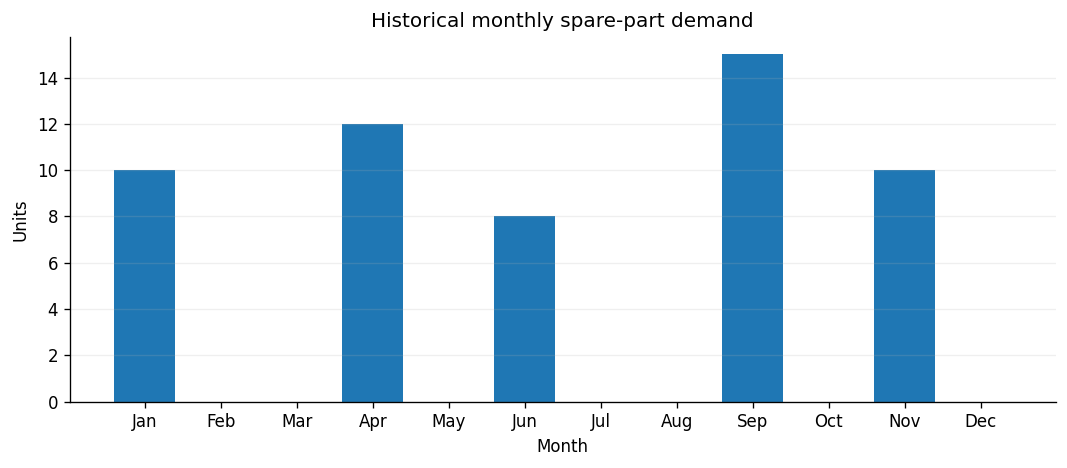

In [2]:
plt.bar(months, demand)
finish('Historical monthly spare-part demand', 'Month', 'Units')

| Historical characteristic | Value        |
| ------------------------- | ------------ |
| Total periods             | 12           |
| Total demand              | 55           |
| Non-zero demand periods   | 5            |
| Zero-demand periods       | 7            |
| ADI                       | 2.40         |
| CV² (positive demand)     | 0.05785      |
| Demand classification     | Intermittent |
| Average monthly demand    | 4.5833       |

## **3. Probability fundamentals**

Before understanding Poisson, we need to understand three basic concepts.

### **3.1 Probability**

Probability measures how likely an event is to occur. It ranges from 0 (impossible) to 1 (certain).

From our historical dataset:

$$ P(\text{Zero demand})=\frac{7}{12}=58.33\\% $$

$$ P(\text{Positive demand})=\frac{5}{12}=41.67\\% $$

These are called **empirical probabilities**, because they are calculated directly from historical observations.

### **3.2 Random variable**

Let:

$$ X=\text{Demand next month} $$

Since future demand is unknown, X is a random variable.

| Expression      | Meaning                          |
| --------------- | -------------------------------- |
| $P(X=0)$    | Probability of zero demand       |
| $P(X=5)$    | Probability of exactly 5 units   |
| $P(X\leq5)$ | Probability of 5 or fewer units  |
| $P(X>5)$    | Probability of more than 5 units |
| $P(X\geq1)$ | Probability of positive demand   |

### **3.3 Discrete vs. continuous distribution**

**Discrete distribution**

Countable values: 0, 1, 2, 3...

Example: Spare-part demand

**Poisson, Negative Binomial**

**Continuous distribution**

Continuous values: 1.2, 1.25, 1.251...

Example: Demand in kilograms

**Gamma**

Poisson is a discrete distribution because it models non-negative integer counts. However, its expected value can be fractional.

## **4. What is Poisson distribution?**

Poisson distribution models the number of events occurring within a fixed interval, such as a day, month or year.

Examples in supply chain management include machine failures, customer orders, warranty claims and spare-part requirements.

The standard homogeneous Poisson process assumes independent events occurring at a constant underlying rate.

### **4.1 Lambda parameter (λ)**

Lambda is the single parameter of the Poisson distribution.

$$ \boxed{\lambda=\text{Expected number of events per period}} $$

| Lambda | Interpretation                  |
| ------ | ------------------------------- |
| 0.5    | Average of 0.5 events per month |
| 1      | Average of 1 event per month    |
| 5      | Average of 5 events per month   |
| 10     | Average of 10 events per month  |

Lambda is an expected count, not a probability. Therefore, it can be greater than 1.

### **4.2 How do we calculate Lambda?**

For a constant-rate Poisson model, Lambda is estimated using the historical arithmetic mean.

$$ \boxed{\hat{\lambda}=\frac{\sum_{t=1}^{n}x_t}{n}} $$

Where:

- $x_t$ = actual demand in period t.
- $n$ = total number of historical periods.
- $\hat{\lambda}$ = estimated Lambda.

Using our dataset:

$$ \hat{\lambda}=\frac{10+0+0+12+0+8+0+0+15+0+10+0}{12} $$

$$ \boxed{\hat{\lambda}=\frac{55}{12}=4.583333} $$

### **4.3 Month-by-month Lambda calculation**

Unlike Croston or TSB, basic Poisson estimation does not require smoothing parameters or separate initialization assumptions.

| Month | Actual demand | Cumulative demand | Periods | Estimated λ |
| ----- | ------------- | ----------------- | ------- | ----------- |
| Jan   | 10            | 10                | 1       | 10.0000     |
| Feb   | 0             | 10                | 2       | 5.0000      |
| Mar   | 0             | 10                | 3       | 3.3333      |
| Apr   | 12            | 22                | 4       | 5.5000      |
| May   | 0             | 22                | 5       | 4.4000      |
| Jun   | 8             | 30                | 6       | 5.0000      |
| Jul   | 0             | 30                | 7       | 4.2857      |
| Aug   | 0             | 30                | 8       | 3.7500      |
| Sep   | 15            | 45                | 9       | 5.0000      |
| Oct   | 0             | 45                | 10      | 4.5000      |
| Nov   | 10            | 55                | 11      | 5.0000      |
| Dec   | 0             | 55                | 12      | **4.5833**  |

The Lambda calculated after December is used for forecasting the following January.

### **4.4 Why do we include zero-demand periods?**

If we exclude zeros:

$$ \frac{55}{5}=11 $$

This represents average demand during positive-demand months, not average demand across all months.

Interestingly:

$$ \frac{5}{12}\times\frac{55}{5} =0.416667\times11 =4.583333 $$

This resembles our previously learned TSB concept:

$$ \text{Forecast}=\text{Demand probability}\times\text{Demand size} $$

However, ordinary Poisson does not independently model these two components, whereas TSB does.

## **5. Poisson Probability Mass Function (PMF)**

Now that we have estimated Lambda, we can calculate the probability of each possible demand quantity.

The Poisson probability formula is:

$$ \boxed{P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!}} $$

This is called the **Probability Mass Function (PMF)**.

### **5.1 Understanding every component**

| Symbol             | Meaning                     | Our example           |
| ------------------ | --------------------------- | --------------------- |
| $X$            | Random variable             | Future monthly demand |
| $k$            | Demand quantity of interest | 0, 1, 2, 3...         |
| $\lambda$      | Expected demand             | 4.583333              |
| $e$            | Euler's constant            | 2.718282              |
| $e^{-\lambda}$ | Negative exponential        | 0.01022077            |
| $\lambda^k$    | Lambda raised to power k    | Depends on k          |
| $k!$           | Factorial of k              | Depends on k          |

### **5.2 Understanding factorial (k!)**

A factorial is the multiplication of all positive integers from 1 to k.

| k | Calculation       | Factorial |
| - | ----------------- | --------- |
| 0 | Defined as 1      | 1         |
| 1 | 1                 | 1         |
| 2 | 2 × 1             | 2         |
| 3 | 3 × 2 × 1         | 6         |
| 4 | 4 × 3 × 2 × 1     | 24        |
| 5 | 5 × 4 × 3 × 2 × 1 | 120       |

Remember:

$$ 0!=1 $$

The factorial originates from the combinatorial mathematics used to derive the Poisson distribution from the Binomial distribution.

### **5.3 Understanding the exponential term**

Euler's number is a mathematical constant:

$$ e=2.718281828... $$

A negative exponent represents a reciprocal:

$$ e^{-\lambda}=\frac{1}{e^\lambda} $$

Using our Lambda:

$$ e^{-4.583333}=0.01022077 $$

This term decreases as Lambda increases.

The exponential term also ensures that probabilities across all possible outcomes sum to 1, because:

$$ \sum_{k=0}^{\infty}\frac{\lambda^k}{k!}=e^\lambda $$

Therefore:

$$ e^{-\lambda}\times e^\lambda=1 $$

## **6. Step-by-step manual probability calculations**

For every calculation, we will use:

$$ \lambda=4.583333 $$

### **Example 1 — Probability of zero demand**

We want to calculate:

$$ P(X=0) $$

Substitute $k=0$:

$$ P(X=0)=\frac{e^{-4.583333}\times4.583333^0}{0!} $$

Calculate each component:

$$ e^{-4.583333}=0.01022077 $$

$$ 4.583333^0=1,\qquad0!=1 $$

Combine the values:

$$ P(X=0)=\frac{0.01022077\times1}{1} $$

$$ \boxed{P(X=0)=1.0221\\%} $$

Therefore, we obtain an important simplified formula:

$$ \boxed{P(X=0)=e^{-\lambda}} $$

### **Example 2 — Probability of exactly one unit**

Substitute $k=1$:

$$ P(X=1)=\frac{e^{-4.583333}\times4.583333^1}{1!} $$

$$ =\frac{0.01022077\times4.583333}{1} $$

$$ =0.0468452 $$

$$ \boxed{P(X=1)=4.6845\\%} $$

### **Example 3 — Probability of exactly two units**

Substitute $k=2$:

$$ P(X=2)=\frac{e^{-4.583333}\times4.583333^2}{2!} $$

Calculate the individual components:

$$ 4.583333^2=21.006944 $$

$$ 2!=2 $$

Therefore:

$$ P(X=2)=\frac{0.01022077\times21.006944}{2} $$

$$ \boxed{P(X=2)=10.7354\\%} $$

### **Example 4 — Probability of exactly three units**

$$ P(X=3)=\frac{e^{-4.583333}\times4.583333^3}{3!} $$

$$ =\frac{0.01022077\times96.281829}{6} $$

$$ \boxed{P(X=3)=16.4012\\%} $$

### **6.1 Complete calculation table**

We can apply the same formula to every possible demand quantity.

| Demand (k) | $\lambda^k$ | k!  | Probability |
| ---------- | --------------- | --- | ----------- |
| 0          | 1.0000          | 1   | 1.0221%     |
| 1          | 4.5833          | 1   | 4.6845%     |
| 2          | 21.0069         | 2   | 10.7354%    |
| 3          | 96.2818         | 6   | 16.4012%    |
| 4          | 441.2915        | 24  | 18.7931%    |
| 5          | 2,022.5860      | 120 | 17.2270%    |

Alternatively, after calculating the first probability, we can calculate successive probabilities using:

$$ P(X=k)=P(X=k-1)\times\frac{\lambda}{k} $$

This avoids repeatedly calculating factorials and exponential terms.

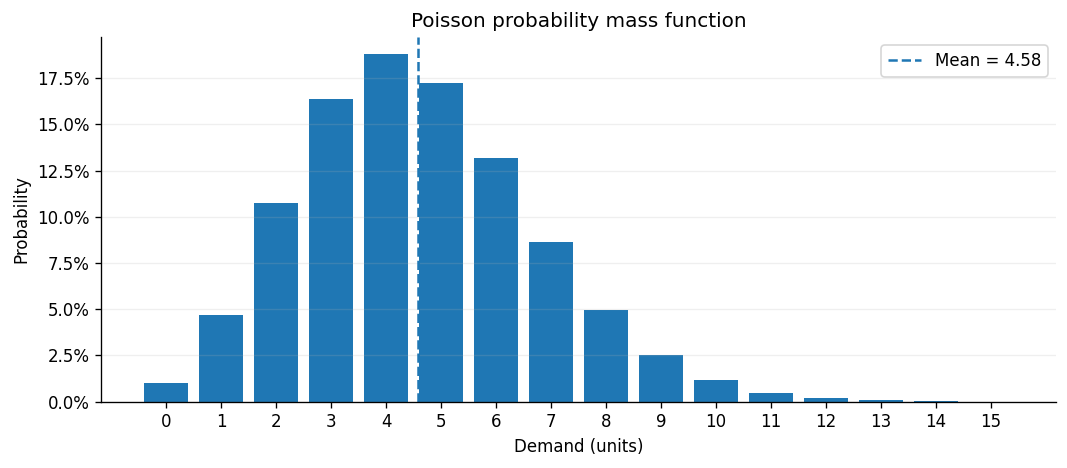

In [3]:
plt.bar(k, poisson.pmf(k, lam))
plt.axvline(lam, linestyle='--', label=f'Mean = {lam:.2f}')
plt.xticks(k); plt.legend()
finish('Poisson probability mass function', 'Demand (units)', 'Probability', True)

Notice that the most probable individual demand quantity is 4 units. This is called the **mode**, whereas the expected demand (mean) is 4.5833 units.

They are not necessarily the same.

## **7. Cumulative Distribution Function (CDF)**

The PMF calculates the probability of exactly k units. The CDF calculates the probability of k units or fewer.

$$ \boxed{P(X\leq k)=\sum_{i=0}^{k}P(X=i)} $$

For example, what is the probability of demand being 5 units or fewer?

$$ P(X\leq5)=P(X=0)+\cdots+P(X=5) $$

$$ \begin{aligned} ={}&0.010221+0.046845+0.107354\\ &+0.164012+0.187931+0.172270 \end{aligned} $$

$$ \boxed{P(X\leq5)=68.8633\\%} $$

Similarly, the probability of demand exceeding 5 units is:

$$ P(X>5)=1-P(X\leq5) $$

$$ \boxed{P(X>5)=31.1367\\%} $$

| Demand (k) | PMF — Exactly k | CDF — k or fewer |
| ---------- | --------------- | ---------------- |
| 0          | 1.0221%         | 1.0221%          |
| 1          | 4.6845%         | 5.7066%          |
| 2          | 10.7354%        | 16.4420%         |
| 3          | 16.4012%        | 32.8432%         |
| 4          | 18.7931%        | 51.6363%         |
| 5          | 17.2270%        | 68.8633%         |
| 6          | 13.1595%        | 82.0228%         |
| 7          | 8.6163%         | 90.6391%         |
| 8          | 4.9364%         | 95.5756%         |
| 9          | 2.5139%         | 98.0895%         |
| 10         | 1.1522%         | 99.2417%         |

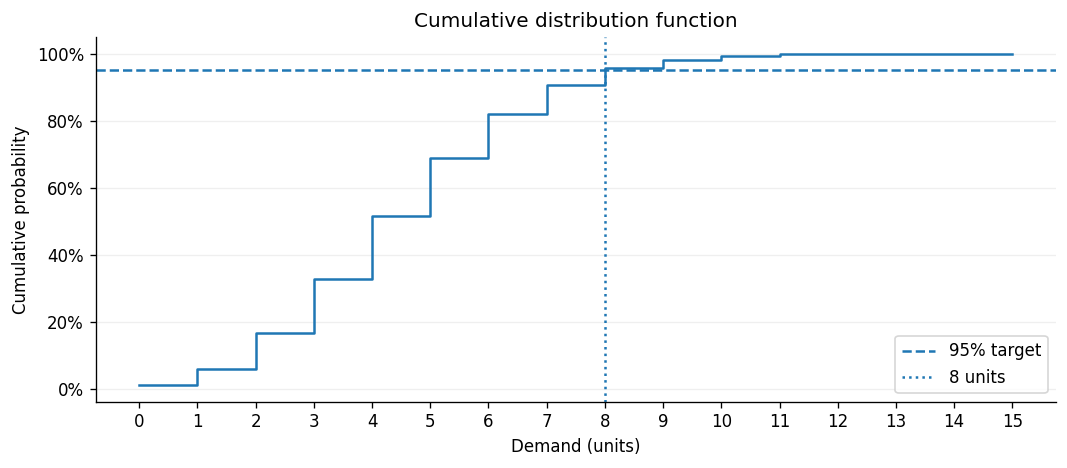

In [4]:
plt.step(k, poisson.cdf(k, lam), where='post')
plt.axhline(.95, linestyle='--', label='95% target'); plt.axvline(8, linestyle=':', label='8 units')
plt.xticks(k); plt.legend()
finish('Cumulative distribution function', 'Demand (units)', 'Cumulative probability', True)

The CDF will become particularly useful when we calculate safety stock and service levels.

## **8. Expected value and variance**

### **8.1 Expected value (Mean)**

Expected value is the probability-weighted average of all possible outcomes.

$$ E[X]=\sum_{k=0}^{\infty}kP(X=k) $$

For example:

| Demand    | Probability | Demand × probability |
| --------- | ----------- | -------------------- |
| 0         | 0.50        | 0.00                 |
| 1         | 0.30        | 0.30                 |
| 2         | 0.20        | 0.40                 |
| **Total** | **1.00**    | **0.70**             |

Therefore, expected demand is 0.7 units.

For the Poisson distribution, substituting the PMF into the expected value formula and simplifying gives:

$$ \boxed{E[X]=\lambda} $$

For our dataset:

$$ \boxed{E[X]=4.583333} $$

This is our expected monthly demand forecast.

### **8.2 Variance**

Variance measures how widely demand quantities are dispersed around their expected value.

Poisson has a special mathematical property:

$$ \boxed{\operatorname{Var}(X)=\lambda} $$

Therefore:

$$ \boxed{E[X]=\operatorname{Var}(X)=\lambda} $$

This property is called **equidispersion**.

For our fitted model:

| Statistic                                 | Value    |
| ----------------------------------------- | -------- |
| Expected demand                           | 4.583333 |
| Variance                                  | 4.583333 |
| Standard deviation ($\sqrt{\lambda}$) | 2.140872 |

Unlike other distributions, ordinary Poisson does not have separate parameters for mean and variance. This is its most important limitation.

## **9. Parameter estimation — Maximum Likelihood Estimation (MLE)**

We calculated Lambda using the historical mean. But why is the arithmetic mean used?

Poisson uses **Maximum Likelihood Estimation (MLE)** as its standard parameter estimation method.

The objective is to find the Lambda value under which our observed historical dataset has the greatest likelihood.

For independent historical observations:

$$ L(\lambda)=\prod_{t=1}^{n} \frac{e^{-\lambda}\lambda^{x_t}}{x_t!} $$

Here, the product symbol means multiplying the probabilities of all historical observations.

Taking the natural logarithm:

$$ \log L(\lambda)= -n\lambda+\sum x_t\log\lambda -\sum\log(x_t!) $$

Differentiating and setting the derivative equal to zero:

$$ -n+\frac{\sum x_t}{\lambda}=0 $$

Rearranging gives:

$$ \boxed{\hat{\lambda}=\frac{\sum x_t}{n}} $$

Therefore:

$$ \hat{\lambda}=\frac{55}{12}=4.583333 $$

MLE explains where the Lambda estimation formula comes from.

Unlike Croston, SBA or TSB, we do not need to select smoothing parameters such as Alpha and Beta for this basic model.

## **10. Lambda sensitivity analysis**

Let's understand what happens to the probability distribution when Lambda changes.

### **Interactive Poisson distribution**

P(X=0): 1.022% | P(X=5): 17.227%
P(X≤5): 68.863% | P(X>5): 31.137%


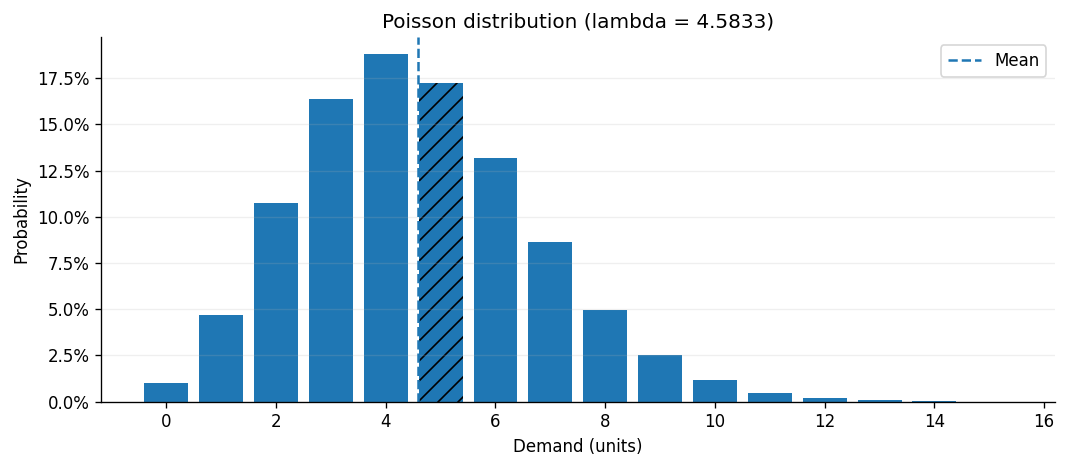

In [5]:
def explore_poisson(rate=lam, selected=5):
    grid = np.arange(max(16, int(poisson.ppf(.9999, rate))+1, selected+1))
    probs = poisson.pmf(grid, rate)
    print(f'P(X=0): {poisson.pmf(0, rate):.3%} | P(X={selected}): {poisson.pmf(selected, rate):.3%}')
    print(f'P(X≤{selected}): {poisson.cdf(selected, rate):.3%} | P(X>{selected}): {poisson.sf(selected, rate):.3%}')
    bars = plt.bar(grid, probs)
    bars[selected].set_hatch('//')
    plt.axvline(rate, linestyle='--', label='Mean'); plt.legend()
    finish(f'Poisson distribution (lambda = {rate:.4f})', 'Demand (units)', 'Probability', True)
explore_poisson()

In [ ]:
# Run this cell in Jupyter/Colab to activate the interactive controls.
try:
    import ipywidgets as widgets
    rate_slider = widgets.FloatSlider(value=lam, min=.0, max=10, step=.1, description='Lambda', readout_format='.4f', continuous_update=False)
    quantity_slider = widgets.IntSlider(value=5, min=0, max=30, description='Demand k', continuous_update=False)
    reset = widgets.Button(description='Reset')
    def reset_controls(_):
        rate_slider.value = lam
        quantity_slider.value = 5
    reset.on_click(reset_controls)
    output = widgets.interactive_output(explore_poisson, {'rate':rate_slider, 'selected':quantity_slider})
    display(widgets.VBox([rate_slider, quantity_slider, reset, output]))
except ImportError:
    print('Install ipywidgets to use sliders; explore_poisson(rate, selected) works without widgets.')

| Lambda | P(Zero demand) | Mean   | Variance |
| ------ | -------------- | ------ | -------- |
| 0.2    | 81.87%         | 0.2    | 0.2      |
| 0.5    | 60.65%         | 0.5    | 0.5      |
| 1.0    | 36.79%         | 1.0    | 1.0      |
| 3.0    | 4.98%          | 3.0    | 3.0      |
| 4.5833 | 1.02%          | 4.5833 | 4.5833   |
| 10.0   | 0.0045%        | 10.0   | 10.0     |

**Key observation:** As Lambda increases, expected demand and variance increase, while the probability of zero demand decreases exponentially.

This is why Poisson can model intermittent demand when the event rate is low.

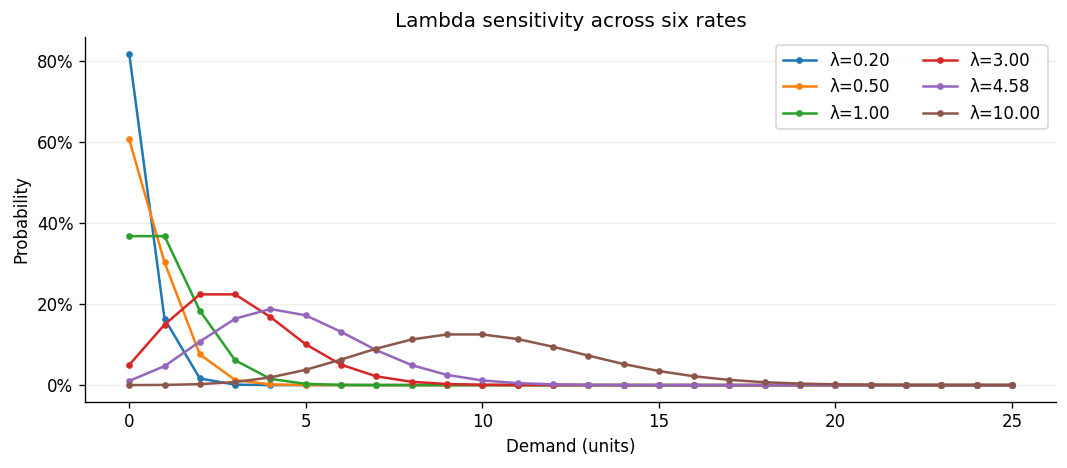

In [6]:
for rate in [.2,.5,1,3,lam,10]:
    grid = np.arange(26)
    plt.plot(grid, poisson.pmf(grid, rate), marker='.', label=f'λ={rate:.2f}')
plt.legend(ncol=2)
finish('Lambda sensitivity across six rates', 'Demand (units)', 'Probability', True)

## **11. Limitations of Poisson — Overdispersion**

This is particularly important for our intermittent demand dataset.

Poisson assumes:

$$ \text{Mean}=\text{Variance} $$

But does our actual historical demand satisfy this assumption?

### **11.1 Calculate historical sample variance**

The sample variance formula is:

$$ s^2=\frac{\sum_{t=1}^{n}(x_t-\bar{x})^2}{n-1} $$

Where:

- $x_t$ = actual historical demand.
- $\bar{x}$ = historical mean (4.583333).
- $n$ = number of observations (12).

| Actual demand | Occurrences | Deviation from mean | Squared deviation |
| ------------- | ----------- | ------------------- | ----------------- |
| 0             | 7           | -4.5833             | 21.0069           |
| 8             | 1           | 3.4167              | 11.6736           |
| 10            | 2           | 5.4167              | 29.3403           |
| 12            | 1           | 7.4167              | 55.0069           |
| 15            | 1           | 10.4167             | 108.5069          |

Multiplying each squared deviation by its number of occurrences and adding:

$$ \sum(x_t-\bar{x})^2=380.916667 $$

Therefore:

$$ s^2=\frac{380.916667}{11} $$

$$ \boxed{s^2=34.628788} $$

### **11.2 Dispersion ratio**

$$ \boxed{\text{Dispersion ratio}=\frac{\text{Variance}}{\text{Mean}}} $$

$$ =\frac{34.628788}{4.583333} $$

$$ \boxed{D=7.5554} $$

| Dispersion ratio | Classification  |
| ---------------- | --------------- |
| Less than 1      | Underdispersion |
| Equal to 1       | Equidispersion  |
| Greater than 1   | Overdispersion  |

Our historical demand variance is approximately 7.56 times its mean, indicating substantial overdispersion relative to ordinary Poisson.

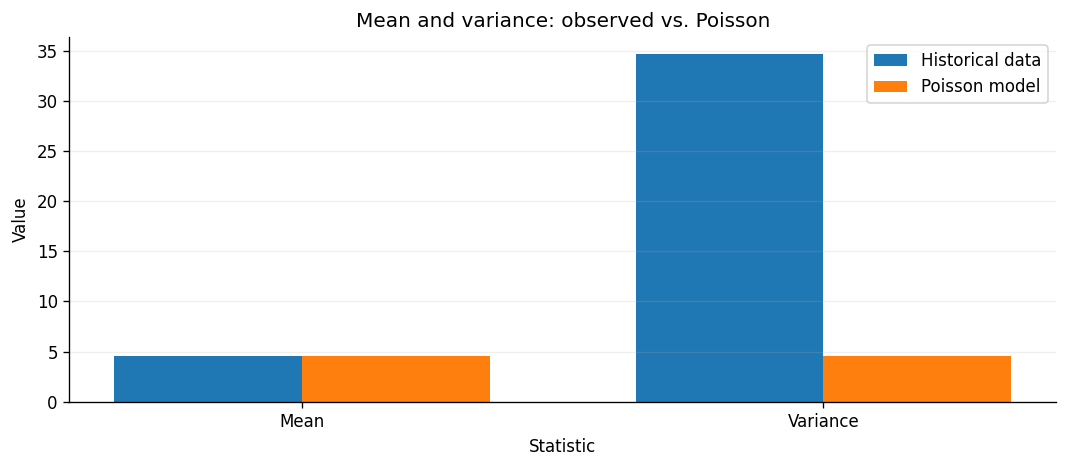

In [7]:
x = np.arange(2)
plt.bar(x-.18, [lam, variance], .36, label='Historical data')
plt.bar(x+.18, [lam, lam], .36, label='Poisson model')
plt.xticks(x, ['Mean','Variance']); plt.legend()
finish('Mean and variance: observed vs. Poisson', 'Statistic', 'Value')

### **11.3 Historical distribution vs. Poisson distribution**

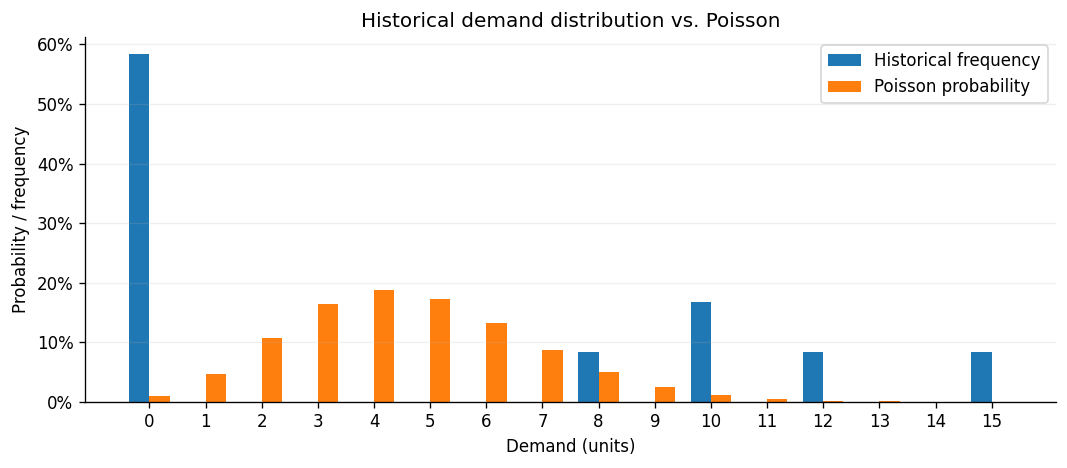

In [8]:
empirical = np.array([(demand == i).mean() for i in k])
plt.bar(k-.18, empirical, .36, label='Historical frequency')
plt.bar(k+.18, poisson.pmf(k, lam), .36, label='Poisson probability')
plt.xticks(k); plt.legend()
finish('Historical demand distribution vs. Poisson', 'Demand (units)', 'Probability / frequency', True)

| Characteristic                        | Historical | Poisson |
| ------------------------------------- | ---------- | ------- |
| Average demand                        | 4.5833     | 4.5833  |
| Variance                              | 34.6288    | 4.5833  |
| Zero-demand probability/frequency     | 58.33%     | 1.02%   |
| Positive-demand probability/frequency | 41.67%     | 98.98%  |
| Most frequent outcome                 | 0          | 4       |

Although Poisson estimates the average demand correctly, it fails to represent the historical demand pattern.

**A correct average forecast does not necessarily mean a correct probability distribution.**

This is the problem that more flexible distributions such as Negative Binomial and Tweedie attempt to address.

### **11.4 When is Poisson suitable for intermittent demand?**

Consider another spare part with the following demand:

In [9]:
demand_new = np.array([0, 1, 0, 0, 2, 0, 1, 0, 0, 1, 0, 1])
print("New SKU mean:", demand_new.mean())

New SKU mean: 0.5


| Characteristic             | Original SKU | New SKU   |
| -------------------------- | ------------ | --------- |
| ADI                        | 2.40         | 2.40      |
| Mean                       | 4.5833       | 0.5000    |
| Sample variance            | 34.6288      | 0.4545    |
| Dispersion ratio           | 7.5554       | 0.9091    |
| Historical zero proportion | 58.33%       | 58.33%    |
| Poisson zero probability   | 1.02%        | 60.65%    |
| Poisson suitability        | Poor         | Plausible |

Both SKUs are intermittent, but the second SKU is much more compatible with Poisson.

This demonstrates why demand classification alone is insufficient for model selection.

## **12. Demand forecasting and inventory optimization**

### **12.1 Future demand forecast**

Since:

$$ E[X]=\lambda $$

Our next six months' forecasts are:

| Future month | Forecast    |
| ------------ | ----------- |
| January      | 4.5833      |
| February     | 4.5833      |
| March        | 4.5833      |
| April        | 4.5833      |
| May          | 4.5833      |
| June         | 4.5833      |
| **Total**    | **27.5000** |

The forecast remains constant because ordinary Poisson does not incorporate trends, seasonality or changing demand rates.

### **12.2 Lead-time demand**

An important property of Poisson is that independent Poisson variables can be added together.

For a fixed lead time of L months:

$$ \boxed{\lambda_L=L\times\lambda} $$

Suppose supplier lead time is three months:

$$ \lambda_L=3\times4.583333=13.75 $$

Therefore:

$$ X_L\sim\operatorname{Poisson}(13.75) $$

Both the expected cumulative demand and the model variance equal 13.75.

### **12.3 Safety stock and service level**

Suppose we want to achieve a 95% cycle service level during a one-month protection period.

We need the smallest inventory quantity S satisfying:

$$ P(X\leq S)\geq0.95 $$

Using our earlier CDF calculations:

| Available inventory | Service level | Stockout probability |
| ------------------- | ------------- | -------------------- |
| 5                   | 68.86%        | 31.14%               |
| 6                   | 82.02%        | 17.98%               |
| 7                   | 90.64%        | 9.36%                |
| **8**               | **95.58%**    | **4.42%**            |
| 9                   | 98.09%        | 1.91%                |
| 10                  | 99.24%        | 0.76%                |

Therefore:

$$ \text{Required inventory}=8 $$

$$ \text{Safety stock}=8-4.583333 $$

$$ \boxed{\text{Safety stock}=3.416667} $$

However, remember that Poisson is a poor fit for our original SKU. Maintaining 8 units would have covered only 8 out of 12 historical months if stock were reset every month.

**Poisson-predicted service level**

95.58%

**Historical demand coverage**

66.67%

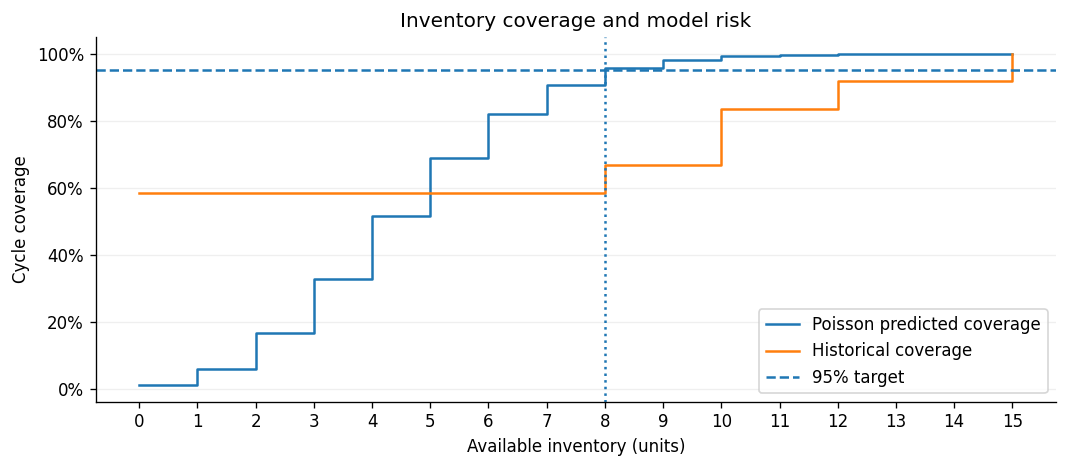

In [10]:
stock = np.arange(16)
plt.step(stock, poisson.cdf(stock, lam), where='post', label='Poisson predicted coverage')
plt.step(stock, [(demand <= i).mean() for i in stock], where='post', label='Historical coverage')
plt.axhline(.95, linestyle='--', label='95% target'); plt.axvline(8, linestyle=':')
plt.legend(); plt.xticks(stock)
finish('Inventory coverage and model risk', 'Available inventory (units)', 'Cycle coverage', True)

This is a retrospective illustration, not an independent backtest. It demonstrates why choosing the right probability distribution is critical for inventory optimization.

## **13. Poisson regression**

Ordinary Poisson assumes a constant Lambda. Poisson regression allows Lambda to change based on explanatory variables such as installed machine population, utilization, seasonality and maintenance schedules.

### **13.1 Mathematical formula**

Traditional linear regression:

$$ \hat y=\beta_0+\beta_1x $$

Poisson regression:

$$ \log(\lambda)=\beta_0+\beta_1x $$

Removing the logarithm:

$$ \boxed{\lambda=e^{\beta_0+\beta_1x}} $$

| Parameter     | Meaning                                 |
| ------------- | --------------------------------------- |
| $\lambda$ | Expected demand conditional on features |
| $\beta_0$ | Intercept                               |
| $\beta_1$ | Regression coefficient                  |
| $x$       | Explanatory variable                    |

The exponential function ensures that predicted demand remains positive.

This is called a **log link function**, and Poisson regression belongs to the Generalized Linear Model (GLM) family.

### **13.2 Manual regression example**

Since our original dataset does not contain explanatory variables, consider this illustrative machine-utilization dataset.

| Period | Utilization (x) | Actual demand |
| ------ | --------------- | ------------- |
| 1      | 0               | 0             |
| 2      | 0               | 1             |
| 3      | 0               | 2             |
| 4      | 0               | 1             |
| 5      | 1               | 2             |
| 6      | 1               | 3             |
| 7      | 1               | 4             |
| 8      | 1               | 3             |

Here, 0 represents normal utilization and 1 represents high utilization.

**Step 1 — Calculate group averages**

Normal utilization:

$$ \lambda_0=\frac{0+1+2+1}{4}=1 $$

High utilization:

$$ \lambda_1=\frac{2+3+4+3}{4}=3 $$

**Step 2 — Calculate intercept**

$$ \log(1)=\beta_0+\beta_1(0) $$

$$ \boxed{\beta_0=0} $$

**Step 3 — Calculate coefficient**

$$ \log(3)=0+\beta_1(1) $$

$$ \boxed{\beta_1=1.098612} $$

**Step 4 — Construct the regression model**

$$ \boxed{\lambda=e^{1.098612x}} $$

**Step 5 — Generate forecasts**

| Machine utilization | x | Forecast calculation | Forecast |
| ------------------- | - | -------------------- | -------- |
| Normal              | 0 | $e^0$            | 1        |
| High                | 1 | $e^{1.098612}$   | 3        |

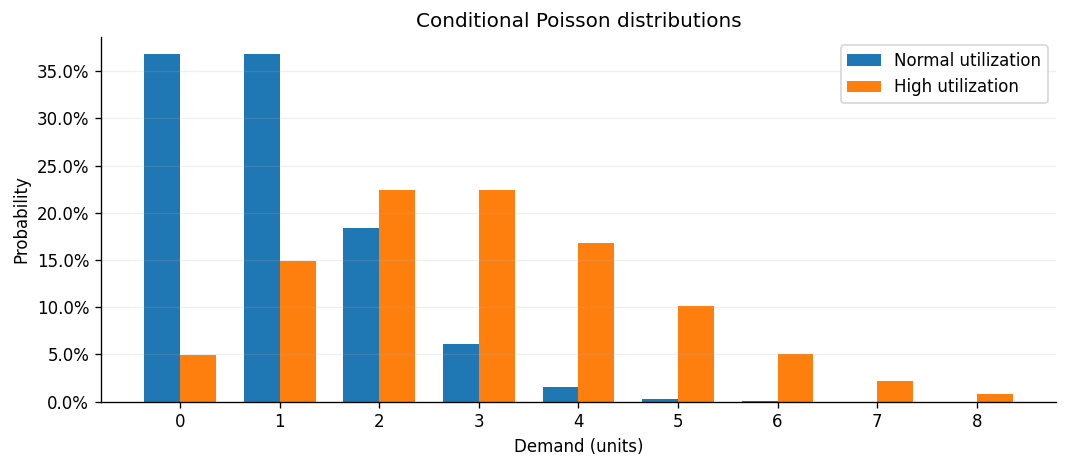

In [11]:
r = np.arange(9)
plt.bar(r-.18, poisson.pmf(r, 1), .36, label='Normal utilization')
plt.bar(r+.18, poisson.pmf(r, 3), .36, label='High utilization')
plt.xticks(r); plt.legend()
finish('Conditional Poisson distributions', 'Demand (units)', 'Probability', True)

Poisson regression changes the expected demand as well as its conditional probability distribution.

The coefficient interpretation is multiplicative:

$$ e^{\beta_1}=3 $$

High utilization is associated with three times the expected demand.

### **13.3 Exposure and offset**

Suppose each machine generates an average of 0.02 failures per month.

| Facility | Installed machines | Expected failures |
| -------- | ------------------ | ----------------- |
| A        | 100                | 2                 |
| B        | 200                | 4                 |

Poisson regression can incorporate this difference using exposure:

$$ \log(\lambda)=\log(E)+\beta_0+\beta_1x $$

Here, E represents exposure, such as installed machines or operating hours. The term $\log(E)$ is called an offset.

### **13.4 Poisson loss and deviance**

When we later study XGBoost, LightGBM and other machine learning algorithms, we will encounter the Poisson loss function.

$$ \boxed{\mathcal L(y,\mu)=\mu-y\log(\mu)} $$

Here, y is actual demand and μ is predicted demand. Minimizing this loss corresponds to maximizing the Poisson likelihood after excluding terms independent of the prediction.

Poisson deviance is another related measure:

$$ D(y,\mu)=2\left[y\log\left(\frac{y}{\mu}\right)-y+\mu\right] $$

For zero actual demand:

$$ D(0,\mu)=2\mu $$

Unlike MAPE, Poisson deviance can handle zero actual demand when predictions are positive.

We will study these loss functions in more detail during Tweedie regression and machine learning.

## **14. Comparison with previously learned methods**

Using our original dataset and previous initialization and smoothing assumptions, the recalculated forecasts are:

| Method  | Forecast |
| ------- | -------- |
| Croston | 5.8014   |
| SBA     | 5.2212   |
| TSB     | 4.6680   |
| ADIDA   | 4.0267   |
| IMAPA   | 4.5278   |
| Poisson | 4.5833   |

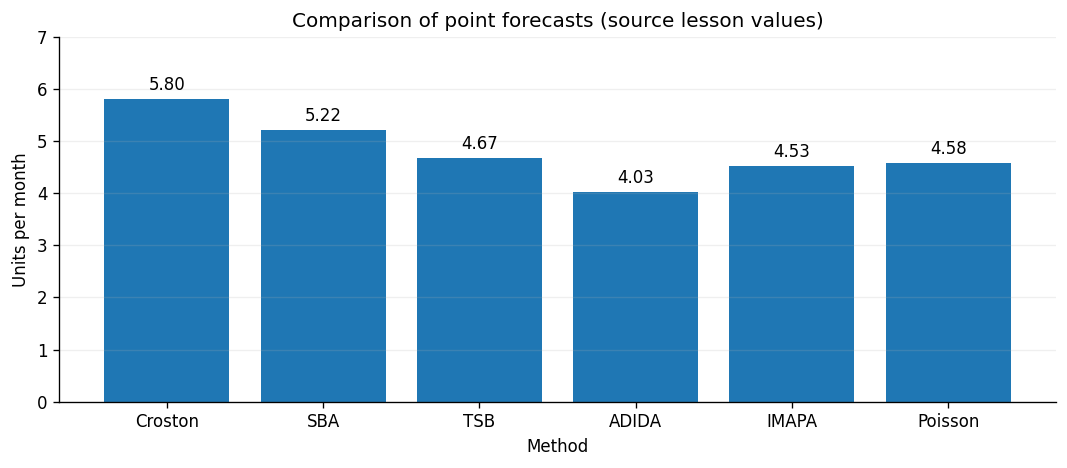

In [12]:
methods = ['Croston','SBA','TSB','ADIDA','IMAPA','Poisson']
forecasts = [5.8014,5.2212,4.6680,4.0267,4.5278,lam]
bars = plt.bar(methods, forecasts)
plt.bar_label(bars, fmt='%.2f', padding=3); plt.ylim(0, 7)
finish('Comparison of point forecasts (source lesson values)', 'Method', 'Units per month')

| Property                             | Croston / SBA | TSB          | ADIDA / IMAPA         | Poisson |
| ------------------------------------ | ------------- | ------------ | --------------------- | ------- |
| Smoothing parameters                 | Yes           | Yes          | Depends on base model | No      |
| Separates demand occurrence and size | Yes           | Yes          | No                    | No      |
| Handles zero demand                  | Yes           | Yes          | Yes                   | Yes     |
| Full probability distribution        | No            | No           | No                    | Yes     |
| Explicit occurrence probability      | No            | Yes          | No                    | Yes     |
| Obsolescence handling                | Limited       | Yes          | Depends on model      | No      |
| Mean–variance restriction            | No            | No           | No                    | Yes     |
| Regression extension                 | Not standard  | Not standard | Depends on model      | Yes     |

Notice how close the TSB and Poisson point forecasts are.

However:

| Statistic                         | TSB    | Poisson |
| --------------------------------- | ------ | ------- |
| Expected demand                   | 4.6680 | 4.5833  |
| Estimated zero-demand probability | 56.57% | 1.02%   |

TSB can independently estimate demand occurrence and magnitude, whereas ordinary Poisson cannot.

Forecast accuracy must ultimately be evaluated through backtesting rather than comparing forecast quantities alone.

## **15. Connection between Poisson, Gamma and Tweedie**

Until now, we have used Poisson to model total demand units directly.

But what if we use Poisson to model the **number of demand events**, and another distribution to model the **size of each demand event**?

Consider the following illustrative order history.

| Month | Number of orders | Individual order quantities | Total demand |
| ----- | ---------------- | --------------------------- | ------------ |
| Jan   | 1                | 10                          | 10           |
| Feb   | 0                | —                           | 0            |
| Mar   | 2                | 4, 8                        | 12           |
| Apr   | 3                | 3, 7, 5                     | 15           |

This introduces the concept of a compound distribution.

**Poisson**

Number of demand events

$N\sim\operatorname{Poisson}(\nu)$

**Gamma**

Magnitude of each event

$W_i\sim\operatorname{Gamma}$

**Compound Poisson–Gamma (Tweedie)**

$$ Y=\sum_{i=1}^{N}W_i $$

Zero demand and positive continuous demand in one distribution (conceptual illustration).

**Conceptual flow:** Poisson event count → independent Gamma event sizes → sum of event sizes. If no events occur, total demand is zero.

### **15.1 Numerical example using our original dataset**

We know that:

$$ P(Y=0)=\frac{7}{12}=0.583333 $$

Let ν represent the Poisson rate of demand events rather than demand units.

$$ P(N=0)=e^{-\nu} $$

Therefore:

$$ e^{-\nu}=0.583333 $$

Taking the natural logarithm:

$$ \nu=-\log(0.583333) $$

$$ \boxed{\nu=0.538997} $$

For independent event magnitudes:

$$ E[Y]=E[N]\times E[W] $$

We already know that expected total monthly demand is 4.583333.

Therefore:

$$ 4.583333=0.538997\times E[W] $$

$$ \boxed{E[W]=8.5035} $$

| Parameter                  | Estimated value |
| -------------------------- | --------------- |
| Expected events per month  | 0.5390          |
| Expected size per event    | 8.5035          |
| Expected monthly demand    | 4.5833          |
| Probability of zero demand | 58.33%          |

Unlike ordinary Poisson, this illustrative compound process can represent our historical mean and zero-demand proportion simultaneously.

These are model-implied event estimates, not observed customer order statistics. We would still need to estimate the magnitude distribution and validate the model.

This is the fundamental idea behind the Compound Poisson–Gamma representation of Tweedie distributions with variance power between 1 and 2.

## **16. Python implementation**

### **16.1 Calculate Lambda and demand statistics**

In [13]:
print("Lambda:", lam)
print("Historical variance:", variance)
print("Dispersion ratio:", dispersion)
print("Historical zero proportion:", np.mean(demand == 0))
print("Poisson zero probability:", poisson.pmf(0, lam))

Lambda: 4.583333333333333
Historical variance: 34.62878787878788
Dispersion ratio: 7.555371900826447
Historical zero proportion: 0.5833333333333334
Poisson zero probability: 0.010220770217146324


### **16.2 Manual Poisson function**

In [14]:
def poisson_pmf(k, lam):
    return math.exp(-lam) * lam ** k / math.factorial(k)
for i in range(3):
    print(i, poisson_pmf(i, lam))

0 0.010220770217146324
1 0.046845196828587315
2 0.1073535760655126


### **16.3 Probability calculations using SciPy**

In [15]:
print("Exactly 5:", poisson.pmf(5, lam))
print("5 or fewer:", poisson.cdf(5, lam))
print("More than 5:", poisson.sf(5, lam))
print("95% quantile:", poisson.ppf(.95, lam))

Exactly 5: 0.17226997702449515
5 or fewer: 0.68863281204033
More than 5: 0.31136718795967006
95% quantile: 8.0


| SciPy function | Purpose                          |
| -------------- | -------------------------------- |
| `pmf()`        | Exact probability                |
| `cdf()`        | Cumulative probability           |
| `sf()`         | Probability exceeding a quantity |
| `ppf()`        | Quantile calculation             |

### **16.4 Probability table and visualization**

,Demand,Probability,Cumulative Probability
0,0,0.010221,0.010221
1,1,0.046845,0.057066
2,2,0.107354,0.164420
3,3,0.164012,0.328432
4,4,0.187931,0.516363
5,5,0.172270,0.688633
6,6,0.131595,0.820228
7,7,0.086163,0.906391
8,8,0.049364,0.955756
9,9,0.025139,0.980895


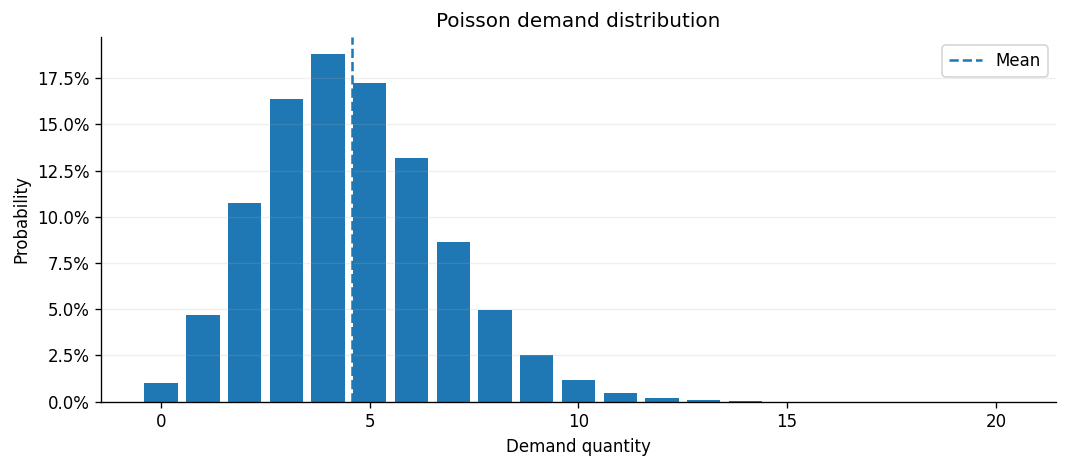

In [16]:
k_table = np.arange(21)
table = pd.DataFrame({'Demand': k_table, 'Probability': poisson.pmf(k_table, lam), 'Cumulative Probability': poisson.cdf(k_table, lam)})
display(table.round(6))
plt.bar(k_table, poisson.pmf(k_table, lam))
plt.axvline(lam, linestyle='--', label='Mean'); plt.legend()
finish('Poisson demand distribution', 'Demand quantity', 'Probability', True)

### **16.5 Reusable forecasting function**

In [17]:
def poisson_forecast(demand, horizon=6, lead_time=1, service_level=0.95):
    lam = np.mean(demand)
    lead_time_mean = lam * lead_time
    return {'Lambda': lam, 'Forecast': np.full(horizon, lam),
            'Probability of Zero': poisson.pmf(0, lam), 'Lead Time Demand': lead_time_mean,
            'Required Stock': poisson.ppf(service_level, lead_time_mean)}
result = poisson_forecast(demand)
print(result)

{'Lambda': np.float64(4.583333333333333), 'Forecast': array([4.58333333, 4.58333333, 4.58333333, 4.58333333, 4.58333333,
       4.58333333]), 'Probability of Zero': np.float64(0.010220770217146324), 'Lead Time Demand': np.float64(4.583333333333333), 'Required Stock': np.float64(8.0)}


### **16.6 Poisson regression**

In [18]:
X = np.array([[0],[0],[0],[0],[1],[1],[1],[1]])
y = np.array([0,1,2,1,2,3,4,3])
model = PoissonRegressor(alpha=0, max_iter=1000, tol=1e-10)
model.fit(X, y)
print('Intercept:', model.intercept_)
print('Coefficient:', model.coef_)
print('Forecast:', model.predict([[0],[1]]))

Intercept: -2.7791567774007734e-09
Coefficient: [1.09861229]
Forecast: [1. 3.]


Expected output, approximately:

```
Intercept: 0.0
Coefficient: [1.098612]
Forecast: [1.0, 3.0]
```

Note that Alpha in `PoissonRegressor` controls regularization, not exponential smoothing.

## **17. Advantages, limitations and model selection**

| Advantages                                | Limitations                                   |
| ----------------------------------------- | --------------------------------------------- |
| Simple parameter estimation               | Mean must equal variance                      |
| Naturally handles zero counts             | Cannot independently control zero probability |
| Provides a full probability distribution  | Struggles with overdispersed demand           |
| Convenient lead-time calculations         | Basic model ignores trend and seasonality     |
| Supports regression and external features | Does not explicitly model batch sizes         |
| Useful for safety stock calculations      | Not a continuous demand distribution          |

### **Enterprise-level model selection**

Historical SKU demand

Demand classification — ADI and CV²

Evaluate mean, variance and zero-demand frequency

**Approximate equidispersion**

Consider Poisson

**Overdispersion / excess zeros**

Consider Negative Binomial, Hurdle, Tweedie

Backtest against competing forecasting models

Select best validated model for each SKU

## **18. Practice questions**

### **Test your understanding**



**1. Total demand is 12 units over 24 months. What is Lambda?**

0.25

0.50

2.00



**2. If Lambda is 0.5, what is the probability of zero demand?**

39.35%

50%

60.65%



**3. If Lambda is 2, what is the probability of exactly 3 units?**

13.53%

18.04%

27.07%



**4. A SKU has mean demand of 4 and variance of 28. What does this indicate?**

Equidispersion

Underdispersion

Overdispersion



**5. Monthly Lambda is 3 and lead time is 4 months. What is expected lead-time demand?**

3

7

12

**Answer key (check after attempting):** 1. 0.50; 2. 60.65%; 3. 18.04%; 4. Overdispersion; 5. 12.

In [19]:
# Verify the numerical quiz answers
print(12/24, poisson.pmf(0,.5), poisson.pmf(3,2), 28/4, 3*4)

0.5 0.6065306597126334 0.18044704431548356 7.0 12


## **19. Important revision formulas**

| Concept                     | Formula                                       |
| --------------------------- | --------------------------------------------- |
| Lambda estimation           | $\hat\lambda=\frac{\sum x_t}{n}$          |
| Poisson PMF                 | $P(X=k)=\frac{e^{-\lambda}\lambda^k}{k!}$ |
| Zero-demand probability     | $P(X=0)=e^{-\lambda}$                     |
| Positive-demand probability | $P(X>0)=1-e^{-\lambda}$                   |
| Expected demand             | $E[X]=\lambda$                            |
| Variance                    | $\operatorname{Var}(X)=\lambda$           |
| Standard deviation          | $\sigma=\sqrt{\lambda}$                   |
| Dispersion ratio            | $D=s^2/\bar{x}$                           |
| Lead-time demand rate       | $\lambda_L=L\lambda$                      |
| Poisson regression          | $\lambda=e^{\beta_0+\beta_1x}$            |
| Compound Poisson mean       | $E[Y]=E[N]E[W]$                           |

### **Final results for our original dataset**

| Parameter                             | Value                   |
| ------------------------------------- | ----------------------- |
| Lambda                                | 4.583333                |
| Forecast                              | 4.583333                |
| P(Zero demand)                        | 1.0221%                 |
| P(Exactly one unit)                   | 4.6845%                 |
| P(Exactly two units)                  | 10.7354%                |
| Poisson variance                      | 4.583333                |
| Historical variance                   | 34.628788               |
| Dispersion ratio                      | 7.5554                  |
| Model-based 95% inventory requirement | 8 units                 |
| Model suitability                     | Poor distributional fit |

The Poisson calculations are reproduced in executable cells. Earlier-method forecasts are carried over from the source lesson; their original smoothing and initialization settings were not supplied.

### **References**

- [NIST — Poisson Distribution](https://www.itl.nist.gov/div898/handbook/eda/section3/eda366j.htm?utm_source=chatgpt.com)
- [SciPy — Poisson Distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html?utm_source=chatgpt.com)
- [Scikit-learn — PoissonRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.PoissonRegressor.html?utm_source=chatgpt.com)
- *Generalized Linear Models* — McCullagh and Nelder.

## **20. Fundamental concept to remember**

**Poisson models the number of events occurring within a fixed interval using a single parameter, Lambda, which determines expected demand, variance and zero-demand probability.**

Its greatest limitation is the restriction:

$$ \boxed{\text{Mean}=\text{Variance}} $$

**Poisson**

How many demand events occur?

**Gamma**

How large is each positive demand event?

**Negative Binomial**

How can we model overdispersed counts?

**Tweedie**

How can we jointly model zero and positive continuous demand?

### **Masterclass progress**

**Overall progress**

6 / 12 completed

1\. Croston

2\. SBA

3\. TSB

4\. ADIDA

5\. IMAPA

6\. Poisson Distribution

7\. Gamma Distribution

Next

8\. Negative Binomial Distribution

9\. Tweedie Distribution and Regression

10\. Hurdle and Zero-Inflated Models

11\. Machine Learning Demand Forecasting

12\. Forecast Evaluation and Inventory Optimization

**Next lesson: Part 7 — Gamma Distribution for Demand Forecasting.**

We will learn how to model positive demand magnitudes using shape, scale and rate parameters, before eventually combining Poisson and Gamma into Tweedie.